# High MOI · Enhancer and promoter perturbations in K562
How does expression of **LMO2** change in cells that carry guides targeting its promoter or a candidate enhancer? The Gasperini et al. at-scale screen measured many guides per cell. We will use its original guide assignments to estimate an element effect and inspect how much of that effect each guide recovers. The bundled extract comes from [GEO GSE120861](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE120861).

## 1. Prepare the count and guide matrices
Start this notebook in `docs/tutorials/`. The input contains 12,000 cells sampled uniformly with seed 12 before inspecting expression or guide carriage. It retains six response genes and both guides for each of four elements. Cells can carry other perturbations from the original screen. A zero in the small guide matrix means none of the **eight displayed guides** was observed. To rebuild the extract from the public data, follow the [input preparation instructions](index.md).

In [1]:
%matplotlib inline
from pathlib import Path
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

source = Path("inputs/gasperini.h5mu")
run = Path("runs/gasperini")
run.mkdir(parents=True, exist_ok=True)

In [2]:
import mudata as mu

with mu.set_options(pull_on_update=False):
    screen = mu.read_h5mu(source)
rna, guides = screen.mod["gene"], screen.mod["guide"]
assert rna.obs_names.equals(guides.obs_names)
mapping = guides.varm["guide_intended_target_pairs"]
elements = guides.uns["intended_targets"]
assert mapping.shape == (guides.n_vars, len(elements))
assert np.all(np.asarray(mapping.sum(axis=1)).ravel() == 1)
# Count distinct cells with any guide for an element.
carriers = (guides.X > 0) @ mapping > 0
print(f"{rna.n_obs:,} cells; median original guide count: {rna.obs['guide_count'].median():g}")
pd.DataFrame({"guides": np.asarray(mapping.sum(axis=0)).ravel(),
              "cells carrying ≥1 guide": np.asarray(carriers.sum(axis=0)).ravel()}, index=elements)

12,000 cells; median original guide count: 29


,guides,cells carrying ≥1 guide
ACTB_TSS,2,96
LMO2_TSS,2,74
chr11.1735_top_two,2,81
random_1,2,52


## 2. Fit element effects and test associations
The guide mapping groups the two guides targeting each element. Relative mode fits a parent element effect and a guide-by-gene efficiency. For testing we use the high-MOI **all-cells** pool and covariate-dependent guide propensity. This keeps cells without a displayed guide in the analysis. The baseline uses up to 10,000 cells and the testing baseline is polished across the analysis cells.

Supply the original RNA library size (`total_umis`) as the offset input. The depth and mitochondrial covariates and preparation batch also enter the design. Summing the six response genes would give a different library-size measure. This small fit runs on CPU in one effect block.

In [3]:
flags = """
--modality-key gene --perturbation-modality-key guide
--perturbation-element-varm-key guide_intended_target_pairs
--perturbation-element-names-uns-key intended_targets --gene-name-key symbol
--library-size-key total_umis --continuous-covariates total_umis percent_mito
--batch-covariate prep_batch --guide-effect-strategy relative --crt-pool all-cells
--size-factor-mode observed --likelihood negbin --prior normal
--num-steps-control 2500 --num-steps-betas 1000 --step-size 0.01 --max-control-cells 10000
--crt --crt-mechanism propensity --crt-tail-families saddlepoint --crt-saddlepoint-only
--crt-two-sided equal-tail --crt-polish-baseline --crt-gene-chunk-size 6 --crt-max-gather-gib 1
--crt-seed 0 --save-model-params --device cpu --no-progress-bar
"""
# Use the CLI in this notebook's Python environment.
command = [sys.executable, "-m", "perturbo.cli", "--input", str(source), "--out-dir", str(run), *shlex.split(flags)]
if (run / "fitted.h5mu").is_file():
    print(f"Using the existing fit in {run}. Choose a fresh run directory to change settings.")
else:
    with (run / "cli.log").open("w") as log:
        result = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
    if result.returncode:
        raise RuntimeError((run / "cli.log").read_text()[-4000:])
    print(f"Fit complete. Output directory: {run}")

Fit complete. Output directory: runs/gasperini


## 3. Inspect the fitted effects

The signed estimate in `posterior_mean` is a natural-log fold change. Negative values indicate lower fitted expression. Here `q_global` is the Benjamini–Hochberg adjustment over all finite element–gene tests in this run. The published rc12 bundle records the same saddlepoint result in `crt_saddlepoint_q_value`. A full-screen analysis has a different testing family.

In [4]:
import mudata
pt = mudata.read_h5mu(run / "fitted.h5mu").uns["_perturbo"]
pairs = pt["effects"]
q = "q_global" if "q_global" in pairs.columns else "crt_saddlepoint_q_value"
tested = pairs.loc[pairs[q].notna()].copy()
assert not tested.duplicated(["element", "gene"]).any()
print(f"{len(tested)} pairs tested; {tested[q].lt(0.1).sum()} at q < 0.1")
tested.nsmallest(6, q)[["element", "gene", "posterior_mean", q]]

24 pairs tested; 10 at q < 0.1


,element,gene,posterior_mean,q_global
16,chr11.1735_top_two,HBG1,-0.782529,9.100552e-08
1,ACTB_TSS,ACTB,-0.660233,1.010733e-06
17,chr11.1735_top_two,LMO2,-1.424034,8.873695e-06
13,chr11.1735_top_two,ACTB,0.265303,5.589863e-03
4,ACTB_TSS,HBG1,0.113743,6.334072e-03
5,ACTB_TSS,LMO2,0.094818,1.496196e-02


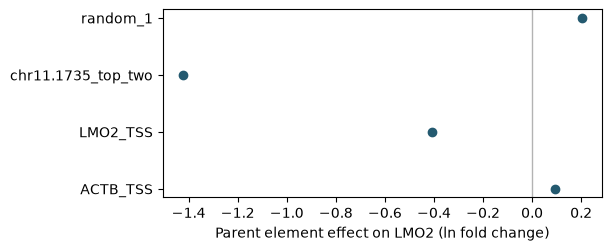

In [5]:
response = tested.loc[tested["gene"].eq("LMO2")].set_index("element").loc[elements]
fig, ax = plt.subplots(figsize=(6, 2.4), layout="constrained")
ax.axvline(0, color="0.7", lw=1)
ax.scatter(response["posterior_mean"], response.index, color="#245a70")
ax.set(xlabel="Parent element effect on LMO2 (ln fold change)", ylabel="")
plt.show()

For an individual guide, the efficiency table reports its fitted multiplier in `guide_relative_efficiency_mean`. Select both the parent element and the response gene.

In [6]:
efficiency = pt["efficiency"]
columns = ["element", "guide", "gene", "guide_relative_efficiency_mean"]
efficiency.loc[efficiency.element.eq("chr11.1735_top_two") & efficiency.gene.eq("LMO2"), columns].rename(
    columns={"guide_relative_efficiency_mean": "relative_efficiency"}
)

,element,guide,gene,relative_efficiency
29,chr11.1735_top_two,GAAATGTTCTACCAGCTACA,LMO2,0.926586
35,chr11.1735_top_two,GCTGTGGCTCAGCCTCCCCA,LMO2,0.823100
